# TP 2 — Classification d'images : ANN puis CNN
**Chapitre 1 · Fondements de l'IA générative** — durée indicative : 2 h

Jeu de données : **Fashion-MNIST** (70 000 images 28×28, 10 classes de vêtements).

Objectifs :
1. Utiliser `Dataset`, `DataLoader` et un découpage entraînement / validation / test.
2. Écrire une boucle d'entraînement et d'évaluation réutilisable.
3. Comparer un réseau dense (ANN) et un réseau convolutif (CNN).
4. Lutter contre le surapprentissage : Dropout, weight decay, arrêt précoce.

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
DATA_DIR = "./data"

PyTorch 2.13.0+cpu | device : cpu


## 1. Données

In [2]:
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
full_train = datasets.FashionMNIST(DATA_DIR, train=True,  download=True, transform=tf)
test_set   = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=tf)

n_val = len(full_train) // 6
train_set, val_set = random_split(full_train, [len(full_train) - n_val, n_val],
                                  generator=torch.Generator().manual_seed(0))
BATCH = 128
train_dl = DataLoader(train_set, batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(val_set,   batch_size=512)
test_dl  = DataLoader(test_set,  batch_size=512)
CLASSES = ["T-shirt", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Basket", "Sac", "Bottine"]
print(len(train_set), len(val_set), len(test_set))

100%|██████████| 26.4M/26.4M [00:10<00:00, 2.49MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 616kB/s]
100%|██████████| 4.42M/4.42M [00:04<00:00, 1.03MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.1MB/s]


50000 10000 10000


torch.Size([128, 1, 28, 28]) torch.Size([128])


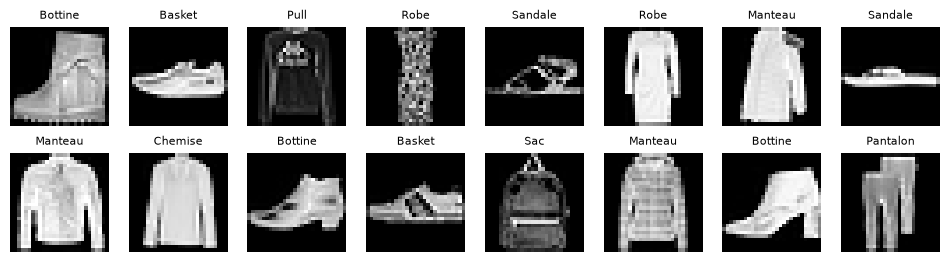

In [4]:
xb, yb = next(iter(train_dl))
print(xb.shape, yb.shape)            # (B, 1, 28, 28), (B,)
fig, ax = plt.subplots(2, 8, figsize=(12, 3))
for i, a in enumerate(ax.flat):
    a.imshow(xb[i, 0], cmap="gray"); a.set_title(CLASSES[yb[i]], fontsize=8); a.axis("off")
plt.show()

**Question.** Pourquoi le jeu de validation est-il séparé du jeu de test ? Que se passerait-il si on choisissait les hyperparamètres sur le jeu de test ?

le model va sur apprend en utilisant les hyperparametres qu'on a utiliser en validation

## 2. Boucle d'entraînement réutilisable

In [6]:
def run_epoch(model, loader, loss_fn, opt=None):
    """Une passe sur loader. Entraîne si opt est fourni, sinon évalue."""
    train = opt is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = loss_fn(logits, y)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(y)
            correct  += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, correct / n

def fit(model, epochs=10, lr=1e-3, wd=0.0, patience=3, ckpt="best.pt"):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.CrossEntropyLoss()
    hist, best, wait = [], float("inf"), 0
    for ep in range(1, epochs + 1):
        tr = run_epoch(model, train_dl, loss_fn, opt)
        va = run_epoch(model, val_dl, loss_fn)
        hist.append((tr, va))
        print(f"ep {ep:2d} | train loss {tr[0]:.3f} acc {tr[1]:.3f} | val loss {va[0]:.3f} acc {va[1]:.3f}")
        if va[0] < best:                       # arrêt précoce sur la perte de validation
            best, wait = va[0], 0
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
            if wait >= patience:
                print("Arrêt précoce"); break
    model.load_state_dict(torch.load(ckpt, map_location=device))
    return hist

def plot_hist(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for k, name in enumerate(["loss", "accuracy"]):
        ax[k].plot([h[0][k] for h in hist], label="train")
        ax[k].plot([h[1][k] for h in hist], label="val")
        ax[k].set_title(f"{title} — {name}"); ax[k].legend()
    plt.show()

## 3. Réseau dense (ANN)

235146 paramètres
ep  1 | train loss 0.537 acc 0.807 | val loss 0.410 acc 0.851
ep  2 | train loss 0.384 acc 0.858 | val loss 0.380 acc 0.860
ep  3 | train loss 0.345 acc 0.872 | val loss 0.354 acc 0.871
ep  4 | train loss 0.313 acc 0.883 | val loss 0.341 acc 0.873
ep  5 | train loss 0.297 acc 0.888 | val loss 0.335 acc 0.878
ep  6 | train loss 0.280 acc 0.896 | val loss 0.339 acc 0.875
ep  7 | train loss 0.262 acc 0.903 | val loss 0.323 acc 0.884
ep  8 | train loss 0.252 acc 0.906 | val loss 0.311 acc 0.886
ep  9 | train loss 0.238 acc 0.911 | val loss 0.354 acc 0.874
ep 10 | train loss 0.228 acc 0.914 | val loss 0.315 acc 0.887


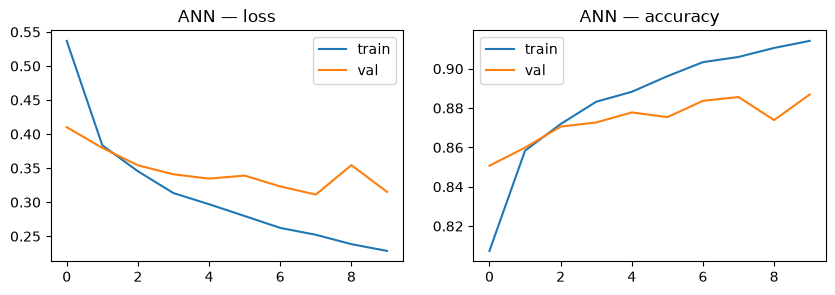

In [7]:
class ANN(nn.Module):
    def __init__(self, p_drop=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 256), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(256, 128),   nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(128, 10))       # logits : pas de softmax (inclus dans CrossEntropyLoss)
    def forward(self, x):
        return self.net(x)

ann = ANN()
print(sum(p.numel() for p in ann.parameters()), "paramètres")
hist_ann = fit(ann, epochs=10, ckpt="ann.pt")
plot_hist(hist_ann, "ANN")

## 4. Réseau convolutif (CNN)

421834 paramètres
ep  1 | train loss 0.429 acc 0.845 | val loss 0.315 acc 0.881
ep  2 | train loss 0.299 acc 0.890 | val loss 0.261 acc 0.902
ep  3 | train loss 0.259 acc 0.904 | val loss 0.245 acc 0.907
ep  4 | train loss 0.235 acc 0.913 | val loss 0.243 acc 0.907
ep  5 | train loss 0.215 acc 0.919 | val loss 0.227 acc 0.915
ep  6 | train loss 0.203 acc 0.924 | val loss 0.233 acc 0.913
ep  7 | train loss 0.188 acc 0.930 | val loss 0.223 acc 0.918
ep  8 | train loss 0.175 acc 0.935 | val loss 0.221 acc 0.917
ep  9 | train loss 0.165 acc 0.938 | val loss 0.204 acc 0.928
ep 10 | train loss 0.156 acc 0.941 | val loss 0.216 acc 0.921


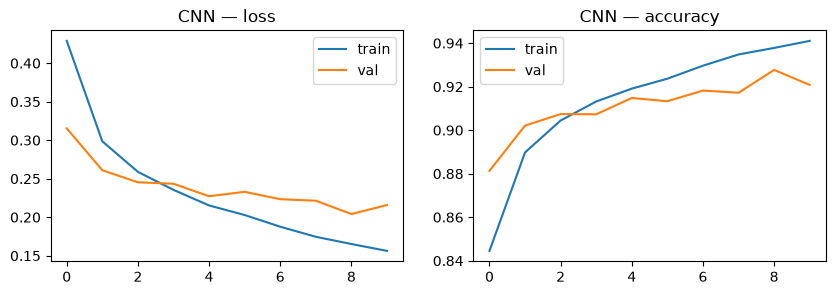

In [8]:
class CNN(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 32×14×14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))  # 64×7×7
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop),
                                  nn.Linear(64*7*7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.head(self.features(x))

cnn = CNN()
print(sum(p.numel() for p in cnn.parameters()), "paramètres")
hist_cnn = fit(cnn, epochs=10, wd=1e-4, ckpt="cnn.pt")
plot_hist(hist_cnn, "CNN")

## 5. Évaluation finale sur le jeu de test

ANN : test acc = 0.877
CNN : test acc = 0.922


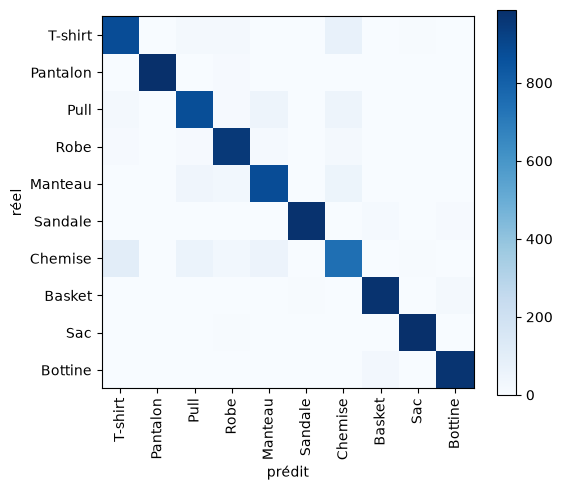

In [9]:
loss_fn = nn.CrossEntropyLoss()
for name, m in [("ANN", ann), ("CNN", cnn)]:
    l, a = run_epoch(m, test_dl, loss_fn)
    print(f"{name} : test acc = {a:.3f}")

# Matrice de confusion du CNN
conf = torch.zeros(10, 10, dtype=torch.long)
cnn.eval()
with torch.no_grad():
    for x, y in test_dl:
        p = cnn(x.to(device)).argmax(1).cpu()
        for t, q in zip(y, p): conf[t, q] += 1
plt.figure(figsize=(6, 5)); plt.imshow(conf, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=90); plt.yticks(range(10), CLASSES)
plt.xlabel("prédit"); plt.ylabel("réel"); plt.colorbar(); plt.show()

## Exercices
1. **Surapprentissage.** Entraînez l'ANN 30 époques sans Dropout (`patience=100`), puis avec `p_drop=0.3`. Décrivez l'écart train/val dans les deux cas.
2. **Analyse d'erreurs.** Quelles paires de classes le CNN confond-il le plus ? Affichez 8 images mal classées.
3. **Architecture.** Ajoutez un troisième bloc convolutif. Le gain justifie-t-il le surcoût en paramètres et en temps ?
4. **Chargement.** Rechargez `cnn.pt` dans un nouveau modèle et vérifiez que la précision de test est identique.

ep  1 | train loss 0.537 acc 0.806 | val loss 0.406 acc 0.854
ep  2 | train loss 0.382 acc 0.861 | val loss 0.366 acc 0.862
ep  3 | train loss 0.338 acc 0.876 | val loss 0.385 acc 0.855
ep  4 | train loss 0.316 acc 0.884 | val loss 0.351 acc 0.870
ep  5 | train loss 0.293 acc 0.891 | val loss 0.361 acc 0.868
ep  6 | train loss 0.279 acc 0.896 | val loss 0.328 acc 0.882
ep  7 | train loss 0.263 acc 0.901 | val loss 0.319 acc 0.883
ep  8 | train loss 0.248 acc 0.908 | val loss 0.328 acc 0.883
ep  9 | train loss 0.237 acc 0.911 | val loss 0.324 acc 0.882
ep 10 | train loss 0.225 acc 0.917 | val loss 0.310 acc 0.890
ep 11 | train loss 0.216 acc 0.919 | val loss 0.370 acc 0.869
ep 12 | train loss 0.210 acc 0.920 | val loss 0.312 acc 0.897
ep 13 | train loss 0.197 acc 0.926 | val loss 0.323 acc 0.889
ep 14 | train loss 0.185 acc 0.931 | val loss 0.320 acc 0.891
ep 15 | train loss 0.182 acc 0.932 | val loss 0.334 acc 0.892
ep 16 | train loss 0.170 acc 0.935 | val loss 0.333 acc 0.888
ep 17 | 

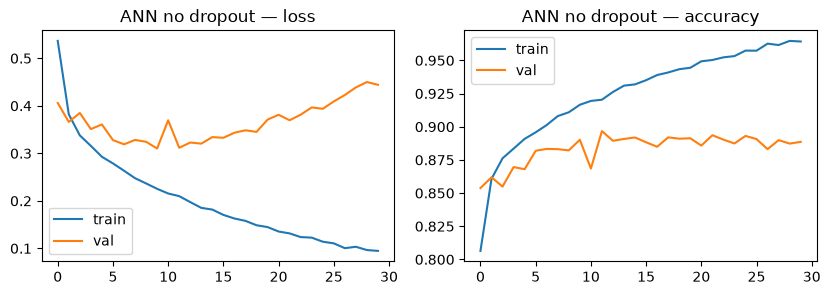

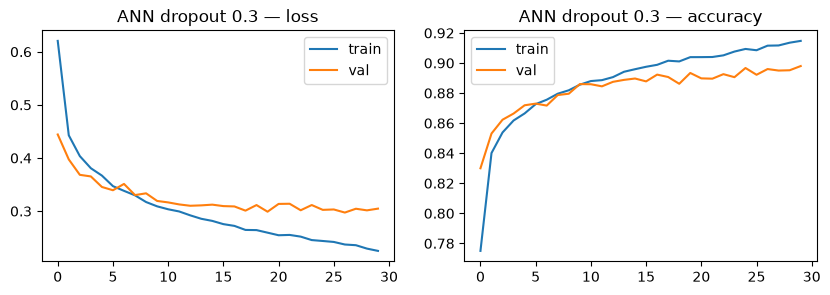

In [10]:
# question 1:
class ANN(nn.Module):
    def __init__(self, p_drop=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28,256),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(128,10)
        )
    def forward(self,x):
        return self.net(x)

ann_no_drop = ANN(p_drop=0.0)
ann_drop = ANN(p_drop=0.3)

hist_no_drop = fit(ann_no_drop, epochs=30, patience=100, ckpt="ann_no_drop.pt")
hist_drop = fit(ann_drop, epochs=30, patience=100, ckpt="ann_drop.pt")

plot_hist(hist_no_drop, "ANN no dropout")
plot_hist(hist_drop, "ANN dropout 0.3")

### analysis of question1:
based on the trainning of 2 diffrent types of ANN, both on 30 epochs:
the first clearly overfits in the taining becaues of the dropout that generaly helps ANNs improve the models ability to generalize

the 2dn has dropout at 0.3 with significantly helps with preventing the Neural netwrok from overfitting

### question2
CNN mostly confuses "Chemise" with "T-shirt", "Pull" and "Manteau", all this analysis is based on the heatmap

### question3
The third block slightly improves performance, but the gain is small compared to the increase in parameters and runtime, so it is not always worth it
sorry i couldnt run it here, it took 25minutes for the 1st to finish, i am sure this new one will take like 32-35 minutes so yea the idea is there, the exec is in a cloud based notebook, kaggle or colab

In [11]:
# question 4
loss_fn = nn.CrossEntropyLoss()

# original trained model
cnn_ref = cnn
l_ref, a_ref = run_epoch(cnn_ref, test_dl, loss_fn)
print(f"Original CNN test acc = {a_ref:.3f}")

# new model loaded from saved file
cnn_loaded = CNN()
cnn_loaded.load_state_dict(torch.load("cnn.pt", map_location=device))
cnn_loaded.to(device)
cnn_loaded.eval()

l_loaded, a_loaded = run_epoch(cnn_loaded, test_dl, loss_fn)
print(f"Loaded CNN test acc = {a_loaded:.3f}")

# compare
print("Same accuracy ?", abs(a_ref - a_loaded) < 1e-3)

Original CNN test acc = 0.922
Loaded CNN test acc = 0.922
Same accuracy ? True
